# Лабораторная работа 1. Численные методы линейной алгебры в задаче наименьших квадратов

## 1. Цель и постановка задачи

Линейная регрессия предсказывает ответ как $X\beta$, а метод наименьших квадратов (МНК) подбирает $\beta$ так, чтобы сумма квадратов ошибок была минимальной. В минимуме остаток $y-X\hat\beta$ ортогонален каждому столбцу $X$, и из этого условия сразу получаются нормальные уравнения.

Все методы ниже математически решают одну и ту же задачу, но численно ведут себя по-разному. Нас интересует, когда эта разница становится заметной и как на неё влияют стандартизация, обусловленность и потеря ранга. Сравниваем LU-разложение нормальных уравнений, разложение Холецкого, метод Зейделя и решение через сингулярное разложение (SVD), а затем смотрим, что дают усечённое SVD и ridge-регуляризация.

Для матрицы признаков со столбцом единиц $X$ и вектора прочности $y$ решаем задачу
$$
\min_\beta \|X\beta-y\|_2^2,\qquad
A\beta=b,\quad A=X^\top X,\quad b=X^\top y.
$$

Качество прогноза измеряем через $\mathrm{RMSE}=\sqrt{\frac1n\sum_i(\hat y_i-y_i)^2}$ в МПа. Для численного сравнения используем два относительных остатка: нормальных уравнений $\|A\beta-b\|_2/\|b\|_2$ и исходной задачи МНК $\|X\beta-y\|_2/\|y\|_2$. Первый показывает, насколько точно решена система. Второй включает ещё и ошибку самой линейной модели, поэтому до нуля не опускается даже при точном решении.

Номера вида «§ 1.4.2» в заголовках отсылают к пунктам задания.

## 2. Исходные данные

Каждая строка таблицы описывает один испытанный образец бетона. Признаки задают состав смеси и возраст образца, целевая переменная равна измеренной прочности на сжатие.

**Concrete Compressive Strength**, I.-C. Yeh (1998), UCI Machine Learning Repository, [источник](https://doi.org/10.24432/C5PK67), [статья](https://doi.org/10.1016/S0008-8846(98)00165-3). Используем поставляемый с работой файл `data/Concrete_Data.xls`, преобразованный в формат `csv`. Единицы и порядок столбцов указаны в `data/Concrete_Readme.txt`.

| Столбец | Содержание | Единицы |
|---|---|---|
| `cement` | Цемент | кг/м³ |
| `slag` | Доменный шлак | кг/м³ |
| `fly_ash` | Зола-унос | кг/м³ |
| `water` | Вода | кг/м³ |
| `superplasticizer` | Суперпластификатор | кг/м³ |
| `coarse_aggregate` | Крупный заполнитель | кг/м³ |
| `fine_aggregate` | Мелкий заполнитель | кг/м³ |
| `age` | Возраст образца | дни |
| `strength` | Измеренная прочность на сжатие, целевая переменная | МПа |

Для запуска требуется ядро Python с пакетами из `requirements.txt`. Факторизации, треугольные системы и SVD берём из SciPy и NumPy. Итерацию Зейделя записываем сами по её матричной формуле.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning, cho_factor, cho_solve, lu_factor, lu_solve, solve_triangular
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler


FEATURES = [
    "cement", "slag", "fly_ash", "water", "superplasticizer",
    "coarse_aggregate", "fine_aggregate", "age",
]
TARGET = "strength"
SEED = 42

data_path = Path("data/Concrete_Data.csv")
if not data_path.is_file():
    data_path = Path("lab-1") / data_path

data = pd.read_csv(data_path)
data.columns = [*FEATURES, TARGET]
data = data.apply(pd.to_numeric, errors="raise")
missing_count = int(data.isna().sum().sum())
assert len(data) == 1030 and missing_count == 0

groups = data.groupby(FEATURES, sort=False).ngroup().to_numpy()
strength_counts = data.groupby(FEATURES)[TARGET].nunique()
display(data.head())
display(pd.Series({
    "Наблюдений": len(data),
    "Признаков": len(FEATURES),
    "Пропусков": missing_count,
    "Уникальных комбинаций признаков": np.unique(groups).size,
    "Комбинаций с разной измеренной прочностью": int((strength_counts > 1).sum()),
}).to_frame("Количество"))

,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,Количество
Наблюдений,1030
Признаков,8
Пропусков,0
Уникальных комбинаций признаков,996
Комбинаций с разной измеренной прочностью,9


Пропусков нет, поэтому используем все 1030 строк. Несколько комбинаций признаков встречаются с разной прочностью: это обычный разброс лабораторных испытаний. Заодно это показывает, что прочность не восстанавливается из признаков детерминированно, как и требует задание.

### 2.1. Подготовка обучающей и тестовой частей

На обучающей части оцениваем коэффициенты, на отложенной тестовой измеряем ошибку прогноза. Около 20% групп отводим под тест с `random_state=42` и используем это разбиение во всех опытах.

Группой считаем строки с совпадающими значениями всех восьми признаков, включая возраст. Группа целиком попадает в одну часть, иначе тест частично проверял бы, как модель запомнила обучающие строки. Одна и та же смесь, испытанная в разном возрасте, даёт строки с разными признаками, поэтому такие строки могут оказаться в разных частях. Для изучения численных методов этого достаточно.

Стандартизатор обучаем только на обучающих строках и применяем к тестовым. Свободный член задаём первым столбцом единиц и сохраняем во всех задачах, включая усечённое SVD. В ridge-регрессии его не штрафуем. Параметр ridge выбираем групповой кросс-валидацией внутри обучающей части.

In [2]:
def add_intercept(features):
    return np.column_stack((np.ones(features.shape[0]), features))


splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(data, groups=groups))
assert len(np.intersect1d(groups[train_idx], groups[test_idx])) == 0

features = data[FEATURES].to_numpy(dtype=float)
target = data[TARGET].to_numpy(dtype=float)
train_raw, test_raw = features[train_idx], features[test_idx]
y_train, y_test = target[train_idx], target[test_idx]

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)
X_train_raw = add_intercept(train_raw)
X_train = add_intercept(train_scaled)
X_test = add_intercept(test_scaled)

display(pd.DataFrame({
    "Наблюдения": [len(train_idx), len(test_idx)],
    "Группы": [np.unique(groups[train_idx]).size, np.unique(groups[test_idx]).size],
}, index=["Обучение", "Тест"]))

,Наблюдения,Группы
Обучение,826,796
Тест,204,200


Доля тестовых строк немного отличается от 20%: разбиение отбирает группы, а в группах разное число строк.

## 3. Исследование матрицы данных (§ 1.4.1)

Ранг показывает, сколько линейно независимых направлений есть среди столбцов матрицы. Число обусловленности показывает, во сколько раз относительное возмущение данных может усилиться в решении. Обе величины удобно читать по сингулярным значениям: если они сильно разбросаны, то изменение коэффициентов в одних направлениях почти не меняет прогноз, а в других меняет сильно.

Численный ранг равен числу сингулярных значений $\sigma_i>\tau$, где
$$\tau=\max(n,p)\,\varepsilon_{\mathrm{mach}}\,\sigma_{\max}.$$
Это тот же порог, что по умолчанию использует `numpy.linalg.matrix_rank`. При полном столбцовом ранге $\kappa_2(X)=\sigma_{\max}/\sigma_{\min}$. Число $\kappa_2(X^\top X)$ считаем по сформированной матрице. В точной арифметике оно равно $\kappa_2(X)^2$, но в почти вырожденной задаче округление при умножении может сдвинуть наименьшее сингулярное значение $X^\top X$. Если численный ранг $X$ неполный, обе обусловленности отмечаем как бесконечные.

Ранг и обусловленность считаем для матрицы со столбцом единиц, корреляции Пирсона считаем по восьми признакам обучающей части.

Корреляции при стандартизации не меняются. Сдвиг не влияет на ковариацию, а деление на $\sigma_x$ и $\sigma_y$ одинаково масштабирует числитель и знаменатель:
$$
r(x',y') = \frac{\operatorname{cov}(x',y')}{\operatorname{std}(x')\operatorname{std}(y')} = \frac{\operatorname{cov}(x,y)}{\sigma_x\sigma_y} = r(x,y).
$$
Поэтому ниже одна тепловая карта, а совпадение корреляций в двух шкалах проверяем в коде. Число обусловленности, наоборот, зависит от масштаба столбцов, и как раз его стандартизация может заметно уменьшить.

,Ранг,Допуск,κ₂(X),κ₂(XᵀX)
До стандартизации,9,6.81e-09,1.063e+05,1.13e+10
После стандартизации,9,7.89e-12,8.608,74.09


,До стандартизации,После стандартизации
Номер σ,,
1,3.716e+04,43.04
2,3305,34.44
3,2620,33.25
4,2433,28.89
5,1809,28.74
6,1397,28.42
7,709.1,25.54
8,104.3,12.01
9,0.3496,5


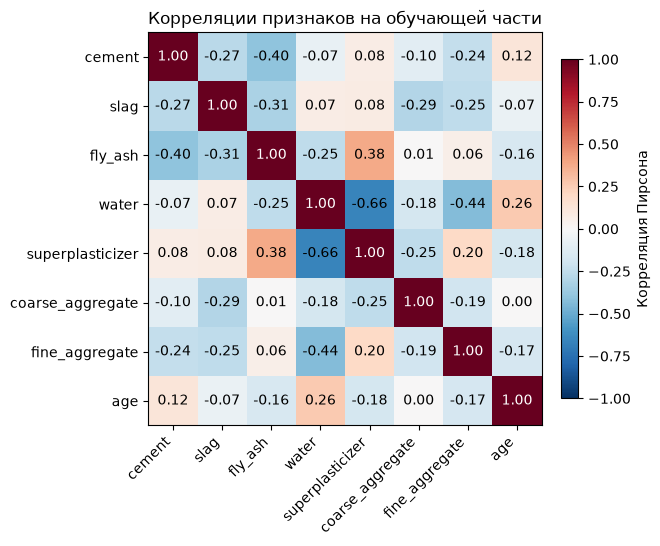

Ранг в обеих шкалах полный: 9 из 9. Стандартизация уменьшила κ₂(X) с 1.06e+05 до 8.61, а κ₂(XᵀX) с 1.13e+10 до 74.1. Сильнее всего связаны `water` и `superplasticizer` (r = -0.66).

In [3]:
def rank_threshold(matrix, singular_values):
    return max(matrix.shape) * np.finfo(matrix.dtype).eps * singular_values[0]


def matrix_diagnostics(matrix):
    singular_values = np.linalg.svd(matrix, compute_uv=False)
    threshold = rank_threshold(matrix, singular_values)
    rank = int(np.count_nonzero(singular_values > threshold))
    full_rank = rank == matrix.shape[1]
    return {
        "Ранг": rank,
        "Допуск": threshold,
        "κ₂(X)": singular_values[0] / singular_values[-1] if full_rank else np.inf,
        "κ₂(XᵀX)": np.linalg.cond(matrix.T @ matrix) if full_rank else np.inf,
    }, singular_values


raw_diagnostics, raw_sigma = matrix_diagnostics(X_train_raw)
scaled_diagnostics, scaled_sigma = matrix_diagnostics(X_train)

display(pd.DataFrame({
    "До стандартизации": raw_diagnostics,
    "После стандартизации": scaled_diagnostics,
}).T.style.format({"Ранг": "{:.0f}", "Допуск": "{:.2e}", "κ₂(X)": "{:.4g}", "κ₂(XᵀX)": "{:.4g}"}))

display(pd.DataFrame({
    "До стандартизации": raw_sigma,
    "После стандартизации": scaled_sigma,
}, index=pd.Index(range(1, len(raw_sigma) + 1), name="Номер σ")).style.format("{:.4g}"))

corr_raw = pd.DataFrame(train_raw, columns=FEATURES).corr()
corr_scaled = pd.DataFrame(train_scaled, columns=FEATURES).corr()
np.testing.assert_allclose(corr_raw, corr_scaled, atol=1e-12)

fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
image = ax.imshow(corr_scaled, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.set_title("Корреляции признаков на обучающей части")
for row, values in enumerate(corr_scaled.to_numpy()):
    for col, value in enumerate(values):
        color = "white" if abs(value) > 0.68 else "black"
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, shrink=0.8, label="Корреляция Пирсона")
plt.show()

correlations = corr_raw.where(np.triu(np.ones(corr_raw.shape, dtype=bool), k=1)).stack()
strongest_pair = correlations.abs().idxmax()
strongest_value = correlations.loc[strongest_pair]
display(Markdown(
    f"Ранг в обеих шкалах полный: {scaled_diagnostics['Ранг']} из {X_train.shape[1]}. "
    f"Стандартизация уменьшила κ₂(X) с {raw_diagnostics['κ₂(X)']:.3g} до {scaled_diagnostics['κ₂(X)']:.3g}, "
    f"а κ₂(XᵀX) с {raw_diagnostics['κ₂(XᵀX)']:.3g} до {scaled_diagnostics['κ₂(XᵀX)']:.3g}. "
    f"Сильнее всего связаны `{strongest_pair[0]}` и `{strongest_pair[1]}` (r = {strongest_value:.2f})."
))

Почти весь выигрыш дало выравнивание масштабов. В исходной шкале столбцы различаются на порядки: компоненты смеси измеряются сотнями кг/м³, возраст измеряется днями, а столбец свободного члена состоит из единиц. Отсюда огромный разброс сингулярных значений. После стандартизации у всех признаков единичная дисперсия, и разброс определяется уже настоящими связями между ними.

Сильной мультиколлинеарности в данных нет: наибольшая по модулю корреляция умеренная, а число обусловленности стандартизованной матрицы порядка десяти. Отрицательная связь воды и суперпластификатора ожидаема: суперпластификатор добавляют как раз для того, чтобы сохранить подвижность смеси при меньшем количестве воды. Парные корреляции не замечают зависимостей сразу между несколькими столбцами, такие зависимости видны только по сингулярным значениям.

## 4. Прямое решение нормальных уравнений (§ 1.4.2)

LU-разложение с перестановками записывает матрицу системы как $PA=LU$, где $P$ переставляет строки, а $L$ и $U$ являются нижней и верхней треугольными матрицами. Система решается двумя подстановками: прямой находим $z$ из $Lz=Pb$, обратной находим $\beta$ из $U\beta=z$. Явную обратную матрицу не вычисляем.

Задание предлагает выбрать метод Гаусса или LU-разложение, мы берём LU и сверяем его с `numpy.linalg.solve`. Для нашей матрицы естественнее разложение Холецкого $A=LL^\top$: при полном столбцовом ранге $X$ матрица $A=X^\top X$ симметрична и положительно определена, а Холецкий вдвое дешевле LU и не требует перестановок. Его применимость проверяем отдельно, как требует задание.

In [4]:
def solve_lu(matrix, rhs):
    with warnings.catch_warnings():
        warnings.simplefilter("error", LinAlgWarning)
        factor = lu_factor(matrix)
    return lu_solve(factor, rhs)


def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))


def relative_residual(matrix, beta, rhs):
    return np.linalg.norm(matrix @ beta - rhs) / np.linalg.norm(rhs)


def evaluate(beta, train_matrix, test_matrix, normal_matrix, rhs):
    return {
        "‖β‖₂": np.linalg.norm(beta),
        "Отн. остаток норм. ур.": relative_residual(normal_matrix, beta, rhs),
        "Отн. остаток МНК": relative_residual(train_matrix, beta, y_train),
        "RMSE обучение, МПа": rmse(y_train, train_matrix @ beta),
        "RMSE тест, МПа": rmse(y_test, test_matrix @ beta),
    }


def baseline_metrics(beta):
    return evaluate(beta, X_train, X_test, A, b)


A = X_train.T @ X_train
b = X_train.T @ y_train
beta_lu = solve_lu(A, b)
beta_reference = np.linalg.solve(A, b)
direct_solutions = {"LU": beta_lu, "numpy.linalg.solve": beta_reference}

try:
    chol = cho_factor(A, lower=True)
except np.linalg.LinAlgError as error:
    display(Markdown(
        f"Разложение Холецкого остановлено: {error} "
        f"Ранг X равен {scaled_diagnostics['Ранг']} из {X_train.shape[1]}, "
        f"минимальное собственное число A равно {np.linalg.eigvalsh(A)[0]:.3e}."
    ))
else:
    direct_solutions["Холецкий"] = cho_solve(chol, b)
    display(Markdown(
        "Разложение Холецкого существует: "
        f"минимальное собственное число A равно {np.linalg.eigvalsh(A)[0]:.3g}."
    ))

coefficient_names = ["Свободный член", *FEATURES]
display(pd.DataFrame(direct_solutions, index=coefficient_names).style.format("{:.6f}"))
direct_results = pd.DataFrame({
    name: baseline_metrics(beta) for name, beta in direct_solutions.items()
}).T
direct_results["‖β − β_LU‖₂"] = [
    np.linalg.norm(beta - beta_lu) for beta in direct_solutions.values()
]
display(direct_results.style.format("{:.4g}"))

display(Markdown(
    f"Решения совпадают: коэффициенты отличаются от LU не больше чем на {direct_results['‖β − β_LU‖₂'].max():.1e}, "
    f"тестовый RMSE равен {direct_results.loc['LU', 'RMSE тест, МПа']:.3f} МПа."
))

Разложение Холецкого существует: минимальное собственное число A равно 25.

,LU,numpy.linalg.solve,Холецкий
Свободный член,36.023049,36.023049,36.023049
cement,12.621078,12.621078,12.621078
slag,8.473261,8.473261,8.473261
fly_ash,5.131771,5.131771,5.131771
water,-3.423330,-3.423330,-3.423330
superplasticizer,2.109488,2.109488,2.109488
coarse_aggregate,1.387876,1.387876,1.387876
fine_aggregate,1.658256,1.658256,1.658256
age,6.908694,6.908694,6.908694


,‖β‖₂,Отн. остаток норм. ур.,Отн. остаток МНК,"RMSE обучение, МПа","RMSE тест, МПа",‖β − β_LU‖₂
LU,40.29,8.301e-17,0.2588,10.31,10.65,0
numpy.linalg.solve,40.29,8.301e-17,0.2588,10.31,10.65,0
Холецкий,40.29,1.518e-16,0.2588,10.31,10.65,8.674e-14


Решения совпадают: коэффициенты отличаются от LU не больше чем на 8.7e-14, тестовый RMSE равен 10.646 МПа.

Два остатка отвечают на разные вопросы. Остаток нормальных уравнений на уровне машинной точности означает, что система решена почти точно, то есть остаток прогноза почти ортогонален столбцам $X$. Остаток МНК далёк от нуля, но это уже свойство модели, а не метода: линейная зависимость от состава и возраста описывает прочность бетона лишь приближённо. Минимальное собственное число $A$ положительно и далеко от нуля, поэтому Холецкий здесь применим без оговорок.

## 5. Итерационное решение (§ 1.4.3)

Метод Зейделя по очереди уточняет коэффициенты. Пересчитывая очередной коэффициент, он сразу использует уже обновлённые значения предыдущих и прошлые значения остальных.

В матричной записи $A=M+U$, где $M$ содержит нижний треугольник вместе с диагональю, а $U$ строго верхний треугольник. Итерация имеет вид
$$\beta^{(k+1)}=\beta^{(k)}+M^{-1}(b-A\beta^{(k)}),$$
а ошибка на каждом шаге умножается на итерационную матрицу $T=-M^{-1}U$. Матрицу $T$ находим решением треугольной системы, без обращения $M$.

**Прогноз до запуска.** Для симметричной положительно определённой матрицы метод Зейделя сходится из любого начального приближения (теорема Островского — Райха). Поэтому вопрос не в том, сойдётся ли метод, а в том, как быстро. Ошибка асимптотически убывает как $\rho(T)^k$, и для уменьшения в $1/\mathrm{tol}$ раз нужно около $\ln\mathrm{tol}/\ln\rho(T)$ итераций. Оценка грубая: она описывает ошибку, а останавливаемся мы по остатку.

Начальное приближение нулевое. Итерации останавливаются, когда относительный остаток нормальных уравнений не превышает $10^{-10}$, лимит составляет 20 000 итераций.

Спектральный радиус ρ(T) = 0.940567 < 1, поэтому метод сойдётся. Если ошибка убывает как ρ(T)ᵏ, допуск 1e-10 будет достигнут примерно за 376 итераций.

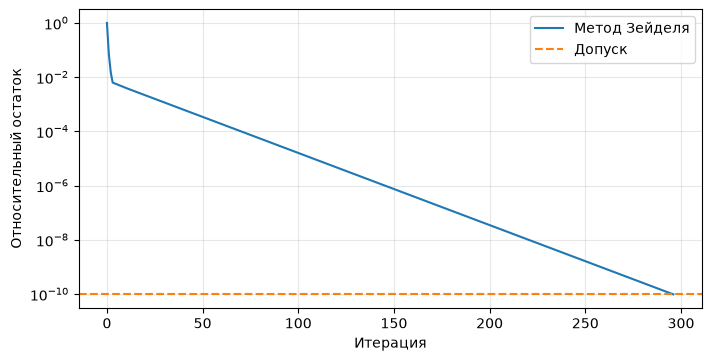

Метод остановился через 296 итераций со статусом «достигнут заданный допуск», итоговый относительный остаток равен 9.72e-11.

In [5]:
TOL = 1e-10
MAX_ITER = 20_000


def prepare_seidel(matrix):
    lower = np.tril(matrix)
    iteration_matrix = solve_triangular(lower, -np.triu(matrix, k=1), lower=True)
    radius = np.max(np.abs(np.linalg.eigvals(iteration_matrix)))
    return lower, radius


def expected_iterations(radius, tolerance):
    if radius >= 1:
        return np.inf
    return int(np.ceil(np.log(tolerance) / np.log(radius)))


def solve_seidel(matrix, rhs, lower, tolerance, max_iterations):
    beta = np.zeros_like(rhs)
    residual = rhs.copy()
    rhs_norm = np.linalg.norm(rhs)
    history = [np.linalg.norm(residual) / rhs_norm]
    status = "Достигнут лимит итераций"

    for _ in range(max_iterations):
        beta += solve_triangular(lower, residual, lower=True)
        residual = rhs - matrix @ beta
        current_residual = np.linalg.norm(residual) / rhs_norm
        history.append(current_residual)
        if not np.isfinite(current_residual):
            status = "Остаток перестал быть конечным"
            break
        if current_residual <= tolerance:
            status = "Достигнут заданный допуск"
            break

    return beta, history, status


lower, rho = prepare_seidel(A)
iterations_forecast = expected_iterations(rho, TOL)
if rho < 1:
    forecast = (
        f"Спектральный радиус ρ(T) = {rho:.6f} < 1, поэтому метод сойдётся. "
        f"Если ошибка убывает как ρ(T)ᵏ, допуск {TOL:g} будет достигнут примерно за {iterations_forecast} итераций."
    )
else:
    forecast = f"Спектральный радиус ρ(T) = {rho:.6f} ≥ 1, сходимость из произвольного приближения не гарантирована."
display(Markdown(forecast))

beta_gs, residual_history, gs_status = solve_seidel(A, b, lower, TOL, MAX_ITER)
iteration = len(residual_history) - 1

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.semilogy(residual_history, label="Метод Зейделя")
ax.axhline(TOL, color="tab:orange", linestyle="--", label="Допуск")
ax.set(xlabel="Итерация", ylabel="Относительный остаток")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

display(Markdown(
    f"Метод остановился через {iteration} итераций со статусом «{gs_status.lower()}», "
    f"итоговый относительный остаток равен {residual_history[-1]:.2e}."
))

Прогноз подтвердился, и фактическое число итераций совпало с оценкой по порядку. Точнее ждать не стоит: $\rho(T)$ задаёт только асимптотический темп, а реальное число шагов зависит ещё от начальной ошибки и от того, что мы следим за остатком, а не за ошибкой. Критерий остановки измеряет точность решения нормальных уравнений, качество прогноза сравним в разделе 6.

### 5.1. Влияние масштаба на итерации

При наличии свободного члена центрирование и масштабирование признаков не меняют пространство линейных прогнозов, но меняют численные свойства задачи. Посмотрим, как метод Зейделя справится с нестандартизованной матрицей при тех же начальном приближении, допуске и лимите итераций.

In [6]:
A_raw = X_train_raw.T @ X_train_raw
b_raw = X_train_raw.T @ y_train
lower_raw, rho_raw = prepare_seidel(A_raw)
iterations_forecast_raw = expected_iterations(rho_raw, TOL)
_, raw_history, raw_status = solve_seidel(A_raw, b_raw, lower_raw, TOL, MAX_ITER)

display(pd.DataFrame({
    "ρ(T)": [rho_raw, rho],
    "Оценка числа итераций": [iterations_forecast_raw, iterations_forecast],
    "Число итераций": [len(raw_history) - 1, iteration],
    "Итоговый относительный остаток": [raw_history[-1], residual_history[-1]],
    "Статус": [raw_status, gs_status],
}, index=["До стандартизации", "После стандартизации"]).style.format({
    "ρ(T)": "{:.6f}", "Итоговый относительный остаток": "{:.2e}",
}))

,ρ(T),Оценка числа итераций,Число итераций,Итоговый относительный остаток,Статус
До стандартизации,0.999765,97997,20000,1.07e-06,Достигнут лимит итераций
После стандартизации,0.940567,376,296,9.72e-11,Достигнут заданный допуск


Без стандартизации $\rho(T)$ отличается от единицы лишь в четвёртом знаке, и оценка числа итераций в несколько раз превышает лимит. Так и вышло: метод заметно продвинулся к решению, но допуска не достиг. Формально он сходится и здесь, ведь матрица по-прежнему симметрична и положительно определена, но пользы от такой сходимости мало.

## 6. Решение через SVD (§ 1.4.4)

Сингулярное разложение записывает матрицу как $X=U\Sigma V^\top$. Столбцы $V$ задают ортонормированные направления в пространстве коэффициентов, столбцы $U$ задают соответствующие направления в пространстве наблюдений, а на диагонали $\Sigma$ стоят сингулярные значения. Решение МНК получается так: проектируем $y$ на направления $U$, делим координаты на сингулярные значения и возвращаемся в исходные координаты через $V$:
$$
\hat\beta_{\mathrm{SVD}}=V_r\Sigma_r^{-1}U_r^\top y.
$$
В сумму входят только направления с $\sigma_i>\tau$, где $\tau$ равен допуску из раздела 3. Если ранг неполный, получаем решение минимальной евклидовой нормы. Результат сверяем с `numpy.linalg.lstsq` с тем же порогом.

Отдельно сравним LU и SVD на нестандартизованной матрице, где $\kappa_2(X^\top X)$ порядка $10^{10}$.

In [7]:
def solve_svd(matrix, rhs):
    left, singular_values, right_t = np.linalg.svd(matrix, full_matrices=False)
    keep = singular_values > rank_threshold(matrix, singular_values)
    return right_t[keep].T @ ((left[:, keep].T @ rhs) / singular_values[keep])


beta_svd = solve_svd(X_train, y_train)
relative_cutoff = max(X_train.shape) * np.finfo(X_train.dtype).eps
beta_lstsq = np.linalg.lstsq(X_train, y_train, rcond=relative_cutoff)[0]
np.testing.assert_allclose(beta_svd, beta_lstsq, rtol=1e-10, atol=1e-10)

beta_lu_raw = solve_lu(A_raw, b_raw)
beta_svd_raw = solve_svd(X_train_raw, y_train)
coef_gap_raw = np.linalg.norm(beta_lu_raw - beta_svd_raw) / np.linalg.norm(beta_svd_raw)
coef_gap_scaled = np.linalg.norm(beta_lu - beta_svd) / np.linalg.norm(beta_svd)
prediction_gap_raw = np.linalg.norm(X_train_raw @ (beta_lu_raw - beta_svd_raw)) / np.linalg.norm(y_train)
prediction_gap_scaled = np.linalg.norm(X_train @ (beta_lu - beta_svd)) / np.linalg.norm(y_train)

baseline_solutions = {"LU": beta_lu}
if "Холецкий" in direct_solutions:
    baseline_solutions["Холецкий"] = direct_solutions["Холецкий"]
baseline_solutions.update({"Зейдель": beta_gs, "SVD": beta_svd})
baseline = pd.DataFrame({
    name: {
        **baseline_metrics(beta),
        "‖β − β_SVD‖₂": np.linalg.norm(beta - beta_svd),
    }
    for name, beta in baseline_solutions.items()
}).T

display(pd.DataFrame(baseline_solutions, index=coefficient_names).style.format("{:.6f}"))
display(baseline.style.format("{:.5g}"))
display(pd.DataFrame({
    "Масштаб признаков": ["Исходный", "Стандартизованный"],
    "‖β_LU − β_SVD‖₂ / ‖β_SVD‖₂": [coef_gap_raw, coef_gap_scaled],
    "‖X(β_LU − β_SVD)‖₂ / ‖y‖₂": [prediction_gap_raw, prediction_gap_scaled],
}).set_index("Масштаб признаков").style.format("{:.2e}"))
display(Markdown(
    f"На стандартизованной задаче коэффициенты LU и Зейделя отличаются от SVD на "
    f"{baseline.loc['LU', '‖β − β_SVD‖₂']:.1e} и {baseline.loc['Зейдель', '‖β − β_SVD‖₂']:.1e}. "
    f"В исходной шкале относительное расхождение коэффициентов LU и SVD равно {coef_gap_raw:.1e}, "
    f"а прогнозов {prediction_gap_raw:.1e}."
))

,LU,Холецкий,Зейдель,SVD
Свободный член,36.023049,36.023049,36.023049,36.023049
cement,12.621078,12.621078,12.621078,12.621078
slag,8.473261,8.473261,8.473261,8.473261
fly_ash,5.131771,5.131771,5.131771,5.131771
water,-3.423330,-3.423330,-3.423330,-3.423330
superplasticizer,2.109488,2.109488,2.109488,2.109488
coarse_aggregate,1.387876,1.387876,1.387876,1.387876
fine_aggregate,1.658256,1.658256,1.658256,1.658256
age,6.908694,6.908694,6.908694,6.908694


,‖β‖₂,Отн. остаток норм. ур.,Отн. остаток МНК,"RMSE обучение, МПа","RMSE тест, МПа",‖β − β_SVD‖₂
LU,40.295,8.3008e-17,0.25883,10.314,10.646,3.7076e-13
Холецкий,40.295,1.5177e-16,0.25883,10.314,10.646,4.5676e-13
Зейдель,40.295,9.7202e-11,0.25883,10.314,10.646,9.9513e-08
SVD,40.295,1.0778e-15,0.25883,10.314,10.646,0


,‖β_LU − β_SVD‖₂ / ‖β_SVD‖₂,‖X(β_LU − β_SVD)‖₂ / ‖y‖₂
Масштаб признаков,,
Исходный,1.30e-11,8.47e-14
Стандартизованный,9.20e-15,1.88e-15


На стандартизованной задаче коэффициенты LU и Зейделя отличаются от SVD на 3.7e-13 и 1.0e-07. В исходной шкале относительное расхождение коэффициентов LU и SVD равно 1.3e-11, а прогнозов 8.5e-14.

На хорошо обусловленной матрице все четыре метода дают один и тот же прогноз: различия в способе вычислений тонут в ошибке самой линейной модели. Расхождение Зейделя на несколько порядков больше, чем у прямых методов, потому что итерации остановлены на допуске $10^{-10}$, а не на машинной точности.

Интереснее исходная шкала. Там формирование $X^\top X$ возводит большое число обусловленности в квадрат, и коэффициенты LU расходятся с SVD заметно сильнее прогнозов. Ошибка решения сосредоточена в направлениях с малыми сингулярными значениями, а сдвиг коэффициентов вдоль такого направления почти не меняет $X\beta$. В следующем разделе тот же эффект проявится намного ярче.

## 7. Искусственное ухудшение обусловленности (§ 1.4.5)

Если один столбец почти выражается через другие, появляется направление, вдоль которого коэффициенты можно сильно менять почти без изменения прогноза. Этому направлению соответствует малое сингулярное значение. Множитель $1/\sigma_i$ в решении через SVD показывает, почему даже небольшая проекция отклика на такое направление превращается в большую компоненту коэффициентов.

К стандартизованным признакам добавляем столбец
$$x_{\mathrm{new}}=x_{\mathrm{cement}}+0.5\,x_{\mathrm{slag}}+\varepsilon z$$
и рассматриваем $\varepsilon$, равные $10^{-2}$, $10^{-6}$ и $0$. Шум $z$ генерируем один раз для всех строк с фиксированным seed 43. Среднее и дисперсию шума приводим к нулю и единице по обучающей части и применяем то же преобразование к тестовой. Шум и разбиение во всех опытах одни и те же.

В численно вырожденном случае LU останавливаем после проверки ранга $X$. Без этой проверки он мог бы «решить» сингулярную систему: из-за округления в $X^\top X$ ведущий элемент формально получается ненулевым. SVD использует только направления выше порога. При $\varepsilon=0$ новый столбец выражается через исходные, поэтому в точной арифметике пространство прогнозов не меняется.

In [8]:
noise = np.random.default_rng(SEED + 1).standard_normal(len(data))
noise_mean = noise[train_idx].mean()
noise_std = noise[train_idx].std()
z_train = (noise[train_idx] - noise_mean) / noise_std
z_test = (noise[test_idx] - noise_mean) / noise_std
assert np.isclose(z_train.var(), 1.0)

j, k = (coefficient_names.index(feature) for feature in ("cement", "slag"))
c = 0.5
dependence_results = []
dependence_diagnostics = []
dependence_coefficients = {}

for epsilon in (1e-2, 1e-6, 0.0):
    train_new = X_train[:, j] + c * X_train[:, k] + epsilon * z_train
    test_new = X_test[:, j] + c * X_test[:, k] + epsilon * z_test
    X_train_aug = np.column_stack((X_train, train_new))
    X_test_aug = np.column_stack((X_test, test_new))
    A_aug = X_train_aug.T @ X_train_aug
    b_aug = X_train_aug.T @ y_train
    diagnostics, singular_values = matrix_diagnostics(X_train_aug)
    label = f"{epsilon:g}"
    dependence_diagnostics.append({
        "ε": label, **diagnostics, "σ_min": singular_values[-1],
    })

    for name in ("LU", "SVD"):
        result = {"ε": label, "Метод": name}
        try:
            if name == "LU":
                if diagnostics["Ранг"] < X_train_aug.shape[1]:
                    raise np.linalg.LinAlgError("X не имеет полного столбцового ранга")
                beta = solve_lu(A_aug, b_aug)
            else:
                beta = solve_svd(X_train_aug, y_train)
            if not np.isfinite(beta).all():
                raise FloatingPointError("Получены нечисловые или бесконечные коэффициенты")
            dependence_coefficients[label, name] = beta
            result.update(evaluate(beta, X_train_aug, X_test_aug, A_aug, b_aug))
            result["Статус"] = "Решение получено"
        except (np.linalg.LinAlgError, LinAlgWarning, FloatingPointError) as error:
            result["Статус"] = str(error)
        dependence_results.append(result)

dependence_matrix = pd.DataFrame(dependence_diagnostics).set_index("ε")
dependence = pd.DataFrame(dependence_results).set_index(["ε", "Метод"])
dependence["‖β_LU − β_SVD‖₂"] = np.nan
for label in dependence_matrix.index:
    if (label, "LU") in dependence_coefficients and (label, "SVD") in dependence_coefficients:
        dependence.loc[(label, "LU"), "‖β_LU − β_SVD‖₂"] = np.linalg.norm(
            dependence_coefficients[label, "LU"] - dependence_coefficients[label, "SVD"]
        )

display(dependence_matrix.style.format({"Ранг": "{:.0f}", **{
    column: "{:.4g}" for column in dependence_matrix.columns if column != "Ранг"
}}))
display(dependence.style.format({
    column: "{:.5g}" for column in dependence.columns if column != "Статус"
}, na_rep="—"))

display(Markdown(
    f"При уменьшении ε с 0.01 до 1e-6 обусловленность X выросла "
    f"с {dependence_matrix.loc['0.01', 'κ₂(X)']:.3g} "
    f"до {dependence_matrix.loc['1e-06', 'κ₂(X)']:.3g}. Норма коэффициентов SVD "
    f"выросла с {dependence.loc[('0.01', 'SVD'), '‖β‖₂']:.3g} "
    f"до {dependence.loc[('1e-06', 'SVD'), '‖β‖₂']:.3g}. "
    f"При ε = 0 ранг уменьшился до {dependence_matrix.loc['0', 'Ранг']}, "
    "а SVD вернул решение минимальной нормы в прежнем пространстве прогнозов."
))

,Ранг,Допуск,κ₂(X),κ₂(XᵀX),σ_min
ε,,,,,
0.01,10,8.422e-12,241,5.81e+04,0.1905
1e-06,10,8.423e-12,2.411e+06,5.801e+12,1.905e-05
0,9,8.423e-12,inf,inf,9.58e-15


При уменьшении ε с 0.01 до 1e-6 обусловленность X выросла с 241 до 2.41e+06. Норма коэффициентов SVD выросла с 117 до 1.21e+06. При ε = 0 ранг уменьшился до 9, а SVD вернул решение минимальной нормы в прежнем пространстве прогнозов.

Норма коэффициентов растёт вместе с обусловленностью, а прогноз почти не меняется. Новый столбец почти равен $x_{\mathrm{cement}}+0.5\,x_{\mathrm{slag}}$, поэтому большой коэффициент при нём почти полностью компенсируется коэффициентами при `cement` и `slag`. При $\varepsilon=10^{-6}$ коэффициенты LU и SVD расходятся на тысячи, хотя норма коэффициентов исходной модели около сорока, а остаток и тестовая ошибка у двух методов почти одинаковые.

При $\varepsilon>0$ обучающий RMSE немного ниже, чем у исходной модели, а тестовый выше: шум $z$ работает как лишний признак, под который модель подстраивается на обучении. При $\varepsilon=0$ LU останавливается проверкой ранга, а SVD отбрасывает нулевое направление и возвращает прогноз исходной модели.

## 8. Сокращение размерности (§ 1.4.6)

Усечённое SVD оставляет направления с наибольшими сингулярными значениями. Для центрированных признаков эти направления совпадают с главными компонентами и описывают наибольшую долю дисперсии признаков. Компоненты выбираются только по матрице признаков, без оглядки на прочность, поэтому их полезность для прогноза проверяем отдельно по RMSE.

Выполняем усечённое SVD стандартизованной обучающей матрицы признаков. Столбец единиц обрабатываем отдельно и сохраняем при всех $k$. Для $k=1,2,3$ и полного доступного ранга используем первые $k$ правых сингулярных векторов $V_k$. Обе части проектируем одним преобразованием $Z=XV_k$ по признакам без столбца единиц. В редуцированной задаче добавляем к $Z$ столбец единиц.

Доля объяснённой дисперсии равна $\sum_{i=1}^k\sigma_i^2 / \sum_i\sigma_i^2$. Число обусловленности рассчитываем для фактической редуцированной матрицы со свободным членом.

,Доля дисперсии,κ₂(X),"RMSE обучение, МПа","RMSE тест, МПа"
k,,,,
1,28.04%,1.498,17.0053,15.3419
2,45.98%,1.498,16.8388,14.9605
3,62.71%,1.498,13.1798,14.2547
8,100.00%,8.608,10.3142,10.6456


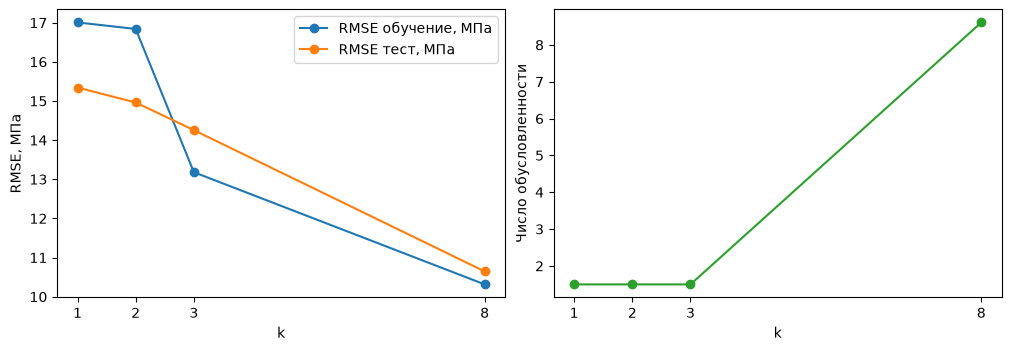

Первые три направления объясняют 62.7% дисперсии. При k = 3 число обусловленности равно 1.50, тестовый RMSE — 14.255 МПа. При полном ранге эти значения составляют соответственно 8.61 и 10.646 МПа.

In [9]:
_, feature_sigma, feature_right_t = np.linalg.svd(train_scaled, full_matrices=False)
feature_rank = int(np.count_nonzero(feature_sigma > rank_threshold(train_scaled, feature_sigma)))
kept_dimensions = [1, 2, 3, feature_rank]
reduction_rows = []

for dimension in kept_dimensions:
    directions = feature_right_t[:dimension].T
    reduced_train = add_intercept(train_scaled @ directions)
    reduced_test = add_intercept(test_scaled @ directions)
    beta_reduced = solve_svd(reduced_train, y_train)
    reduction_rows.append({
        "k": dimension,
        "Доля дисперсии": np.sum(feature_sigma[:dimension] ** 2) / np.sum(feature_sigma ** 2),
        "κ₂(X)": np.linalg.cond(reduced_train),
        "RMSE обучение, МПа": rmse(y_train, reduced_train @ beta_reduced),
        "RMSE тест, МПа": rmse(y_test, reduced_test @ beta_reduced),
    })

reduction = pd.DataFrame(reduction_rows).set_index("k")
np.testing.assert_allclose(reduced_test @ beta_reduced, X_test @ beta_svd, atol=1e-10)
display(reduction.style.format({
    "Доля дисперсии": "{:.2%}", "κ₂(X)": "{:.3f}",
    "RMSE обучение, МПа": "{:.4f}", "RMSE тест, МПа": "{:.4f}",
}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
reduction[["RMSE обучение, МПа", "RMSE тест, МПа"]].plot(ax=axes[0], marker="o")
reduction["κ₂(X)"].plot(ax=axes[1], marker="o", color="tab:green")
axes[0].set(ylabel="RMSE, МПа", xticks=kept_dimensions)
axes[1].set(ylabel="Число обусловленности", xticks=kept_dimensions)
plt.show()

display(Markdown(
    f"Первые три направления объясняют {reduction.loc[3, 'Доля дисперсии']:.1%} "
    f"дисперсии. При k = 3 число обусловленности равно {reduction.loc[3, 'κ₂(X)']:.2f}, "
    f"тестовый RMSE — {reduction.loc[3, 'RMSE тест, МПа']:.3f} МПа. "
    f"При полном ранге эти значения составляют соответственно "
    f"{reduction.loc[feature_rank, 'κ₂(X)']:.2f} и "
    f"{reduction.loc[feature_rank, 'RMSE тест, МПа']:.3f} МПа."
))

С ростом $k$ ошибка падает, но даже три компоненты заметно уступают полной модели. Отброшенные направления имеют малую дисперсию признаков, но несут информацию о прочности.

Одинаковое число обусловленности при $k=1,2,3$ объясняется устройством редуцированной матрицы. Её столбцы ортогональны друг другу и столбцу единиц, поэтому её сингулярные значения равны $\sigma_1,\dots,\sigma_k$ и $\sqrt n$. При $k\le3$ наибольшее из них равно $\sigma_1$, наименьшее равно $\sqrt n$, и отношение от $k$ не зависит. Стандартизованная задача и так хорошо обусловлена, поэтому усечению здесь нечего исправлять.

## 9. Ridge-регуляризация (§ 1.4.7)

Ridge-регрессия добавляет к сумме квадратов ошибок штраф $\lambda\|D\beta\|_2^2$. Чем больше $\lambda$, тем сильнее штраф за большие коэффициенты признаков. Для центрированных признаков действие штрафа можно описать в сингулярных направлениях. В каждом из них обратный множитель $1/\sigma_i$ заменяется на $\sigma_i/(\sigma_i^2+\lambda)$, что особенно сильно подавляет вклад направлений с малыми сингулярными значениями.

Решаем систему $(X^\top X+\lambda D^\top D)\beta_\lambda=X^\top y$, где $D=\operatorname{diag}(0,1,\ldots,1)$. Задание ограничивает сетку пятью-семью значениями, поэтому берём семь значений $\lambda$ от $10^{-4}$ до $10^5$ с одинаковым шагом по логарифму. Малое значение даёт почти нерегуляризованное решение. Верхняя граница позволяет проверить режим сильного сжатия коэффициентов.

**Правило выбора $\lambda$.** Минимизируем средний RMSE по пяти групповым фолдам обучающей части. При равном среднем выбираем меньшее $\lambda$. Стандартизатор заново обучаем внутри каждого фолда. В системе используем сумму квадратов остатков без деления на размер обучающей выборки. Для сопоставимой силы штрафа внутри фолда умножаем $\lambda$ на отношение размера его обучающей части к размеру полной обучающей части. Тестовый RMSE используем для итогового сравнения.

,κ₂ регуляризованной системы,‖β‖₂,‖Dβ‖₂,"RMSE обучение, МПа","RMSE тест, МПа","Средний RMSE по CV, МПа"
λ,,,,,,
0.0001,74.095,40.295,18.055,10.314,10.646,10.498
0.003162,74.086,40.294,18.054,10.314,10.646,10.498
0.1,73.804,40.281,18.024,10.314,10.646,10.498
3.162,65.888,39.916,17.194,10.317,10.662,10.5
100,15.62,37.952,11.946,10.579,10.993,10.741
3162,6.0713,36.136,2.8596,14.757,13.64,14.765
1e+05,123.31,36.023,0.11818,16.94,15.168,16.925


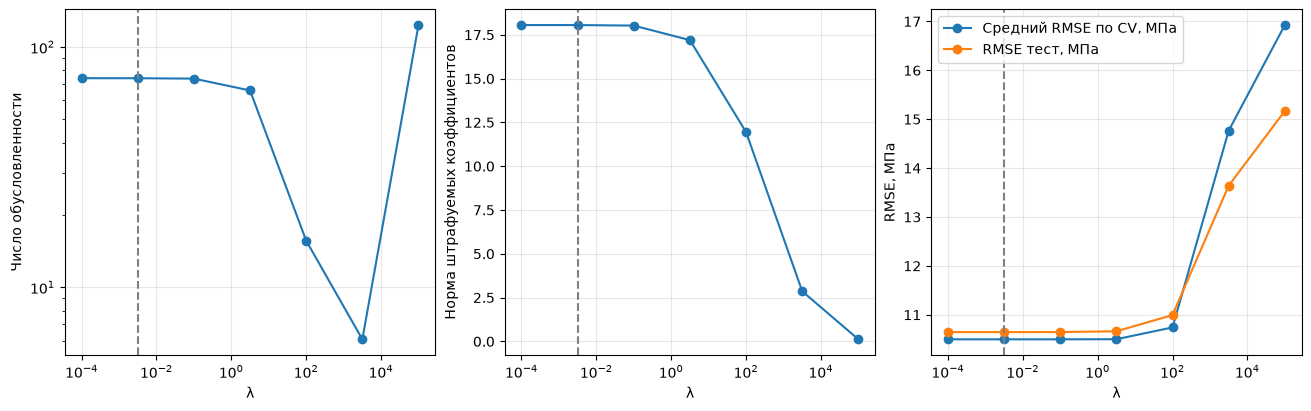

По кросс-валидации выбрано λ = 0.003162. Средний RMSE по фолдам равен 10.498 МПа, тестовый RMSE — 10.646 МПа. При λ = 100000 норма штрафуемых коэффициентов составляет 0.118 против 18.055 при наименьшем λ.

In [10]:
def ridge_system(normal_matrix, penalty, regularization):
    return normal_matrix + regularization * penalty


penalty = np.diag([0.0, *np.ones(len(FEATURES))])
lambdas = np.logspace(-4, 5, num=7)
group_cv = GroupKFold(n_splits=5)
cv_errors = np.empty((len(lambdas), group_cv.n_splits))

for fold, (fit_idx, val_idx) in enumerate(
    group_cv.split(train_raw, y_train, groups=groups[train_idx])
):
    fold_scaler = StandardScaler()
    X_fit = add_intercept(fold_scaler.fit_transform(train_raw[fit_idx]))
    X_val = add_intercept(fold_scaler.transform(train_raw[val_idx]))
    A_fold = X_fit.T @ X_fit
    b_fold = X_fit.T @ y_train[fit_idx]
    fold_scale = len(fit_idx) / len(train_idx)
    for row, regularization in enumerate(lambdas):
        A_reg = ridge_system(A_fold, penalty, regularization * fold_scale)
        beta_fold = solve_lu(A_reg, b_fold)
        cv_errors[row, fold] = rmse(y_train[val_idx], X_val @ beta_fold)

mean_cv_rmse = cv_errors.mean(axis=1)
selected_lambda = lambdas[np.argmin(mean_cv_rmse)]
ridge_rows = []

for regularization, cv_rmse in zip(lambdas, mean_cv_rmse):
    A_reg = ridge_system(A, penalty, regularization)
    beta_ridge = solve_lu(A_reg, b)
    ridge_rows.append({
        "λ": regularization,
        "κ₂ регуляризованной системы": np.linalg.cond(A_reg),
        "‖β‖₂": np.linalg.norm(beta_ridge),
        "‖Dβ‖₂": np.linalg.norm(penalty @ beta_ridge),
        "RMSE обучение, МПа": rmse(y_train, X_train @ beta_ridge),
        "RMSE тест, МПа": rmse(y_test, X_test @ beta_ridge),
        "Средний RMSE по CV, МПа": cv_rmse,
    })

ridge = pd.DataFrame(ridge_rows).set_index("λ")
display(ridge.style.format("{:.5g}").format_index("{:.4g}", axis=0))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
ridge["κ₂ регуляризованной системы"].plot(ax=axes[0], loglog=True, marker="o")
ridge["‖Dβ‖₂"].plot(ax=axes[1], logx=True, marker="o")
ridge[["Средний RMSE по CV, МПа", "RMSE тест, МПа"]].plot(ax=axes[2], logx=True, marker="o")
axes[0].set(ylabel="Число обусловленности")
axes[1].set(ylabel="Норма штрафуемых коэффициентов")
axes[2].set(ylabel="RMSE, МПа")
for ax in axes:
    ax.axvline(selected_lambda, color="0.5", linestyle="--")
    ax.grid(alpha=0.3)
plt.show()

selected_ridge = ridge.loc[selected_lambda]
display(Markdown(
    f"По кросс-валидации выбрано λ = {selected_lambda:.4g}. "
    f"Средний RMSE по фолдам равен {selected_ridge['Средний RMSE по CV, МПа']:.3f} МПа, "
    f"тестовый RMSE — {selected_ridge['RMSE тест, МПа']:.3f} МПа. "
    f"При λ = {lambdas[-1]:.0f} норма штрафуемых коэффициентов составляет "
    f"{ridge.iloc[-1]['‖Dβ‖₂']:.3f} против {ridge.iloc[0]['‖Dβ‖₂']:.3f} "
    "при наименьшем λ."
))

Кросс-валидация выбрала одно из самых малых $\lambda$, то есть по сути отказалась от регуляризации. Это осмысленный результат: признаков мало, наблюдений много, а стандартизованная матрица хорошо обусловлена. Дисперсия МНК-оценки и так невелика, и штраф только добавляет смещение.

Число обусловленности ведёт себя немонотонно. Признаки центрированы, поэтому $A$ распадается на блок свободного члена с собственным числом $n$ и блок признаков, к собственным числам которого штраф прибавляет $\lambda$. Пока $\lambda$ мало, рост малых собственных чисел уменьшает $\kappa$. Когда штрафуемые собственные числа становятся больше $n$, наименьшим остаётся нештрафуемое $n$, и $\kappa$ снова растёт. Лучше всего обусловленная система даёт заметно худший прогноз, так что хорошая обусловленность сама по себе не цель.

## 10. Итоговое сравнение

Все RMSE посчитаны на одних и тех же обучающих и тестовых строках, поэтому их можно сравнивать напрямую. Остаток нормальных уравнений говорит о точности решения системы, тестовый RMSE говорит о качестве прогноза.

Сопоставляем решения МНК, усечённое SVD с заранее выбранными тремя направлениями и ridge с параметром по кросс-валидации. Для масштаба добавляем модель, которая всегда предсказывает среднюю прочность обучающей части. Опыты с искусственно ухудшенной обусловленностью остаются в отдельной таблице раздела 7.

In [11]:
rmse_columns = ["RMSE обучение, МПа", "RMSE тест, МПа"]
mean_strength = y_train.mean()
comparison = pd.concat([
    baseline[rmse_columns],
    reduction.loc[[3], rmse_columns].rename(index={3: "Усечённое SVD, k = 3"}),
    ridge.loc[[selected_lambda], rmse_columns].rename(index={selected_lambda: "Ridge по CV"}),
    pd.DataFrame(
        [[rmse(y_train, mean_strength), rmse(y_test, mean_strength)]],
        columns=rmse_columns, index=["Среднее по обучению"],
    ),
])
display(comparison.style.format("{:.4f}"))

,"RMSE обучение, МПа","RMSE тест, МПа"
LU,10.3142,10.6456
Холецкий,10.3142,10.6456
Зейдель,10.3142,10.6456
SVD,10.3142,10.6456
"Усечённое SVD, k = 3",13.1798,14.2547
Ridge по CV,10.3142,10.6456
Среднее по обучению,17.0397,15.2409


Все четыре способа решить МНК и ridge с выбранным штрафом дают одинаковую ошибку, усечённое SVD заметно хуже. Предсказание средней прочностью ошибается сильнее всех, так что линейная модель многое улавливает. И всё же ошибка около 10 МПа для бетона велика: автор набора данных называет зависимость прочности от состава и возраста сильно нелинейной, а линейная модель эту нелинейность не видит.

## 11. Вопросы для итогового вывода (§ 1.8)

Ответы собираются кодом из результатов выше, поэтому числа в них всегда совпадают с таблицами. Качественные утверждения, на которых держатся выводы, проверяются через `assert`.

In [12]:
test_rmse = baseline["RMSE тест, МПа"]
dep_low, dep_tiny, dep_zero = "0.01", "1e-06", "0"
full = reduction.loc[feature_rank]
condition_numbers = ridge["κ₂ регуляризованной системы"]

assert test_rmse.max() - test_rmse.min() < 1e-3
assert gs_status == "Достигнут заданный допуск" and raw_status == "Достигнут лимит итераций"
assert iterations_forecast_raw > MAX_ITER
assert coef_gap_raw > 10 * coef_gap_scaled
assert dependence.loc[(dep_zero, "LU"), "Статус"] != "Решение получено"
assert reduction["RMSE тест, МПа"].idxmin() == feature_rank
assert abs(ridge.loc[selected_lambda, "RMSE тест, МПа"] - test_rmse["SVD"]) < 1e-3
assert condition_numbers.idxmin() not in (lambdas[0], lambdas[-1])

other_methods = ", ".join(
    f"{name} на {baseline.loc[name, '‖β − β_SVD‖₂']:.1e}" for name in baseline.index if name != "SVD"
)
answers = {
    "Как стандартизация повлияла на обусловленность матрицы и поведение методов?": (
        f"Стандартизация уменьшила κ₂(X) с {raw_diagnostics['κ₂(X)']:.3g} до {scaled_diagnostics['κ₂(X)']:.3g}, "
        f"а κ₂(XᵀX) с {raw_diagnostics['κ₂(XᵀX)']:.3g} до {scaled_diagnostics['κ₂(XᵀX)']:.3g}. "
        f"Ранг остался полным ({scaled_diagnostics['Ранг']}): при свободном члене стандартизация является обратимой заменой "
        "переменных и не меняет пространство прогнозов. Она только выравнивает масштабы столбцов и сжимает разброс "
        "сингулярных значений. Для нормальных уравнений выигрыш больше, поскольку κ₂(XᵀX) = κ₂(X)².\n\n"
        f"Сильнее всего это почувствовал метод Зейделя. Без стандартизации ρ(T) = {rho_raw:.6f}, "
        f"и за {MAX_ITER} итераций он не достиг допуска, а после стандартизации ρ(T) = {rho:.4f}, "
        f"и ему хватило {iteration} итераций. Прямые методы и SVD дали практически одинаковые прогнозы в обеих шкалах."
    ),
    "Совпали ли решения прямого метода, итерационного метода и SVD? Чем объясняются различия?": (
        f"На стандартизованной задаче совпали с точностью вычислений: коэффициенты отличаются от SVD ({other_methods}), "
        f"а тестовый RMSE у всех равен {test_rmse['SVD']:.3f} МПа. У прямых методов расхождение вызвано округлением "
        f"при формировании и решении нормальных уравнений, у Зейделя остановкой на допуске {TOL:g}.\n\n"
        f"В исходной шкале относительное расхождение коэффициентов LU и SVD выросло до {coef_gap_raw:.1e}, "
        f"а прогнозов составило {prediction_gap_raw:.1e}. Ошибка LU сосредоточена в направлениях с малыми "
        "сингулярными значениями, вдоль которых прогноз почти не меняется."
    ),
    "Соответствовала ли фактическая сходимость итерационного метода спектральному прогнозу?": (
        f"Да. Для симметричной положительно определённой A сходимость гарантирована, и ρ(T) = {rho:.4f} < 1. "
        f"По оценке ρ(T)ᵏ ≤ {TOL:g} ожидалось около {iterations_forecast} итераций, понадобилось {iteration}. "
        "Совпадения по порядку здесь и следует ожидать: ρ(T) описывает асимптотику ошибки, а остановка происходит "
        "по остатку.\n\n"
        f"Без стандартизации прогноз тоже подтвердился. При ρ(T) = {rho_raw:.6f} оценка в {iterations_forecast_raw} "
        f"итераций превышает лимит {MAX_ITER}, и метод остановился на лимите с остатком {raw_history[-1]:.1e}."
    ),
    "Как приближение к потере ранга повлияло на коэффициенты, остаток и качество прогноза?": (
        f"Когда ε уменьшилось с 0.01 до 1e-6, σ_min упало с {dependence_matrix.loc[dep_low, 'σ_min']:.3g} "
        f"до {dependence_matrix.loc[dep_tiny, 'σ_min']:.3g}, κ₂(X) выросло с {dependence_matrix.loc[dep_low, 'κ₂(X)']:.3g} "
        f"до {dependence_matrix.loc[dep_tiny, 'κ₂(X)']:.3g}, а норма коэффициентов SVD выросла с "
        f"{dependence.loc[(dep_low, 'SVD'), '‖β‖₂']:.3g} до {dependence.loc[(dep_tiny, 'SVD'), '‖β‖₂']:.3g}. "
        f"Относительный остаток МНК ({dependence.loc[(dep_tiny, 'SVD'), 'Отн. остаток МНК']:.4f}) и тестовый RMSE "
        f"({dependence.loc[(dep_tiny, 'SVD'), 'RMSE тест, МПа']:.3f} МПа) при этом почти не изменились: огромные "
        "коэффициенты при новом столбце, `cement` и `slag` почти компенсируют друг друга.\n\n"
        "Неустойчивость хорошо видна по LU. При ε = 1e-6 его коэффициенты отличаются от SVD на "
        f"{dependence.loc[(dep_tiny, 'LU'), '‖β_LU − β_SVD‖₂']:.3g}, хотя тестовый RMSE равен "
        f"{dependence.loc[(dep_tiny, 'LU'), 'RMSE тест, МПа']:.3f} МПа. При ε = 0 ранг падает до "
        f"{dependence_matrix.loc[dep_zero, 'Ранг']}, LU останавливается проверкой ранга, а SVD возвращает прогноз "
        f"исходной модели с тестовым RMSE {dependence.loc[(dep_zero, 'SVD'), 'RMSE тест, МПа']:.3f} МПа."
    ),
    "Как выбранное сокращение размерности повлияло на устойчивость и ошибку прогноза?": (
        f"Усечение до k ≤ 3 снизило число обусловленности с {full['κ₂(X)']:.3g} до {reduction.loc[3, 'κ₂(X)']:.3g}, "
        f"но тестовый RMSE вырос с {full['RMSE тест, МПа']:.3f} до {reduction.loc[3, 'RMSE тест, МПа']:.3f} МПа "
        f"при k = 3 и до {reduction.loc[1, 'RMSE тест, МПа']:.3f} МПа при k = 1. Три компоненты сохраняют "
        f"{reduction.loc[3, 'Доля дисперсии']:.0%} дисперсии признаков, но отброшенные направления важны для прочности. "
        "Выигрыш в устойчивости здесь не нужен: стандартизованная задача и без того хорошо обусловлена."
    ),
    "Как изменение λ повлияло на обусловленность, коэффициенты и качество ridge-регрессии?": (
        f"С ростом λ норма штрафуемых коэффициентов падает с {ridge['‖Dβ‖₂'].iloc[0]:.3g} до {ridge['‖Dβ‖₂'].iloc[-1]:.3g}, "
        f"и прогноз стремится к средней прочности обучения: тестовый RMSE растёт до {ridge['RMSE тест, МПа'].iloc[-1]:.3f} МПа. "
        f"Число обусловленности сначала падает с {condition_numbers.iloc[0]:.3g} до {condition_numbers.min():.3g} "
        f"при λ ≈ {condition_numbers.idxmin():.4g}, а затем снова растёт до {condition_numbers.iloc[-1]:.3g}, "
        "когда штрафуемые собственные числа обгоняют нештрафуемое собственное число свободного члена.\n\n"
        f"Кросс-валидация выбрала λ = {selected_lambda:.4g}, то есть практически отказалась от регуляризации, "
        f"и тестовый RMSE {ridge.loc[selected_lambda, 'RMSE тест, МПа']:.3f} МПа совпал с МНК. "
        f"При λ с наилучшей обусловленностью тестовый RMSE равен {ridge.loc[condition_numbers.idxmin(), 'RMSE тест, МПа']:.3f} МПа."
    ),
    "Какой способ решения оказался наиболее подходящим для исследованной задачи и почему?": (
        "SVD. На стандартизованной матрице все методы дают одинаковый прогноз, и дешевле всего обошлись бы нормальные "
        "уравнения с разложением Холецкого. Но SVD работает с X напрямую и не возводит обусловленность в квадрат, сам "
        "определяет численный ранг и при его потере возвращает решение минимальной нормы, а не останавливается. "
        "В опыте с ε = 0 только он дал решение. Регуляризация и усечение для этих данных не нужны: ridge по CV "
        "совпал с МНК, а усечённое SVD ухудшило прогноз."
    ),
}
display(Markdown("\n\n".join(
    f"### {number}. {question}\n\n{answer}" for number, (question, answer) in enumerate(answers.items(), 1)
)))

### 1. Как стандартизация повлияла на обусловленность матрицы и поведение методов?

Стандартизация уменьшила κ₂(X) с 1.06e+05 до 8.61, а κ₂(XᵀX) с 1.13e+10 до 74.1. Ранг остался полным (9): при свободном члене стандартизация является обратимой заменой переменных и не меняет пространство прогнозов. Она только выравнивает масштабы столбцов и сжимает разброс сингулярных значений. Для нормальных уравнений выигрыш больше, поскольку κ₂(XᵀX) = κ₂(X)².

Сильнее всего это почувствовал метод Зейделя. Без стандартизации ρ(T) = 0.999765, и за 20000 итераций он не достиг допуска, а после стандартизации ρ(T) = 0.9406, и ему хватило 296 итераций. Прямые методы и SVD дали практически одинаковые прогнозы в обеих шкалах.

### 2. Совпали ли решения прямого метода, итерационного метода и SVD? Чем объясняются различия?

На стандартизованной задаче совпали с точностью вычислений: коэффициенты отличаются от SVD (LU на 3.7e-13, Холецкий на 4.6e-13, Зейдель на 1.0e-07), а тестовый RMSE у всех равен 10.646 МПа. У прямых методов расхождение вызвано округлением при формировании и решении нормальных уравнений, у Зейделя остановкой на допуске 1e-10.

В исходной шкале относительное расхождение коэффициентов LU и SVD выросло до 1.3e-11, а прогнозов составило 8.5e-14. Ошибка LU сосредоточена в направлениях с малыми сингулярными значениями, вдоль которых прогноз почти не меняется.

### 3. Соответствовала ли фактическая сходимость итерационного метода спектральному прогнозу?

Да. Для симметричной положительно определённой A сходимость гарантирована, и ρ(T) = 0.9406 < 1. По оценке ρ(T)ᵏ ≤ 1e-10 ожидалось около 376 итераций, понадобилось 296. Совпадения по порядку здесь и следует ожидать: ρ(T) описывает асимптотику ошибки, а остановка происходит по остатку.

Без стандартизации прогноз тоже подтвердился. При ρ(T) = 0.999765 оценка в 97997 итераций превышает лимит 20000, и метод остановился на лимите с остатком 1.1e-06.

### 4. Как приближение к потере ранга повлияло на коэффициенты, остаток и качество прогноза?

Когда ε уменьшилось с 0.01 до 1e-6, σ_min упало с 0.191 до 1.9e-05, κ₂(X) выросло с 241 до 2.41e+06, а норма коэффициентов SVD выросла с 117 до 1.21e+06. Относительный остаток МНК (0.2580) и тестовый RMSE (10.767 МПа) при этом почти не изменились: огромные коэффициенты при новом столбце, `cement` и `slag` почти компенсируют друг друга.

Неустойчивость хорошо видна по LU. При ε = 1e-6 его коэффициенты отличаются от SVD на 2.98e+03, хотя тестовый RMSE равен 10.767 МПа. При ε = 0 ранг падает до 9, LU останавливается проверкой ранга, а SVD возвращает прогноз исходной модели с тестовым RMSE 10.646 МПа.

### 5. Как выбранное сокращение размерности повлияло на устойчивость и ошибку прогноза?

Усечение до k ≤ 3 снизило число обусловленности с 8.61 до 1.5, но тестовый RMSE вырос с 10.646 до 14.255 МПа при k = 3 и до 15.342 МПа при k = 1. Три компоненты сохраняют 63% дисперсии признаков, но отброшенные направления важны для прочности. Выигрыш в устойчивости здесь не нужен: стандартизованная задача и без того хорошо обусловлена.

### 6. Как изменение λ повлияло на обусловленность, коэффициенты и качество ridge-регрессии?

С ростом λ норма штрафуемых коэффициентов падает с 18.1 до 0.118, и прогноз стремится к средней прочности обучения: тестовый RMSE растёт до 15.168 МПа. Число обусловленности сначала падает с 74.1 до 6.07 при λ ≈ 3162, а затем снова растёт до 123, когда штрафуемые собственные числа обгоняют нештрафуемое собственное число свободного члена.

Кросс-валидация выбрала λ = 0.003162, то есть практически отказалась от регуляризации, и тестовый RMSE 10.646 МПа совпал с МНК. При λ с наилучшей обусловленностью тестовый RMSE равен 13.640 МПа.

### 7. Какой способ решения оказался наиболее подходящим для исследованной задачи и почему?

SVD. На стандартизованной матрице все методы дают одинаковый прогноз, и дешевле всего обошлись бы нормальные уравнения с разложением Холецкого. Но SVD работает с X напрямую и не возводит обусловленность в квадрат, сам определяет численный ранг и при его потере возвращает решение минимальной нормы, а не останавливается. В опыте с ε = 0 только он дал решение. Регуляризация и усечение для этих данных не нужны: ridge по CV совпал с МНК, а усечённое SVD ухудшило прогноз.

## 12. Вклад участников команды

Лабораторную работу выполнили совместно Самойленко Артём и Архипов Прохор. Отдельные задания между участниками не распределялись. Оба готовили данные, реализовывали методы, проверяли результаты и оформляли выводы. Вклад в каждый пункт работы был примерно равным.